In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/debarshichanda/goemotions/GoEmotionsFormat.PNG
/kaggle/input/datasets/debarshichanda/goemotions/README.md
/kaggle/input/datasets/debarshichanda/goemotions/analyze_data.py
/kaggle/input/datasets/debarshichanda/goemotions/calculate_metrics.py
/kaggle/input/datasets/debarshichanda/goemotions/extract_words.py
/kaggle/input/datasets/debarshichanda/goemotions/goemotions_model_card.pdf
/kaggle/input/datasets/debarshichanda/goemotions/replace_emotions.py
/kaggle/input/datasets/debarshichanda/goemotions/data/dev.tsv
/kaggle/input/datasets/debarshichanda/goemotions/data/ekman_labels.csv
/kaggle/input/datasets/debarshichanda/goemotions/data/ekman_mapping.json
/kaggle/input/datasets/debarshichanda/goemotions/data/emotions.txt
/kaggle/input/datasets/debarshichanda/goemotions/data/sentiment_dict.json
/kaggle/input/datasets/debarshichanda/goemotions/data/sentiment_mapping.json
/kaggle/input/datasets/debarshichanda/goemotions/data/test.tsv
/kaggle/input/datasets/debarshichanda/g

In [2]:
!pip -q install -U transformers datasets accelerate evaluate gensim gradio seaborn

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.51.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


In [25]:
import os, re, glob, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    confusion_matrix, precision_recall_fscore_support
)
from sklearn.utils.class_weight import compute_class_weight

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

CLASS_NAMES = ["joy", "sadness", "anger", "fear", "surprise", "disgust"]
NUM_CLASSES = len(CLASS_NAMES)
MAX_LEN = 40
BATCH_SIZE = 128
EPOCHS = 5

LABEL_GROUPS = {
    "joy": ["joy", "amusement", "excitement", "gratitude", "love", "optimism", "pride", "relief"],
    "sadness": ["sadness", "grief", "remorse", "disappointment"],
    "anger": ["anger", "annoyance", "disapproval"],
    "fear": ["fear", "nervousness"],
    "surprise": ["surprise", "realization"],
    "disgust": ["disgust"]
}

Device: cuda


In [10]:
DATA_DIR = "/kaggle/input/datasets/debarshichanda/goemotions/data"

def load_data(filename):
    return pd.read_csv(
        os.path.join(DATA_DIR, filename),
        sep="\t",
        header=None,
        names=["text", "labels", "id"],
        dtype=str,
        keep_default_na=False
    )

train_raw = load_data("train.tsv")
dev_raw = load_data("dev.tsv")
test_raw = load_data("test.tsv")

with open(os.path.join(DATA_DIR, "emotions.txt"), "r", encoding="utf-8") as f:
    emotion_names = [line.strip() for line in f if line.strip()]

train_raw = train_raw.drop_duplicates(subset=["id"]).reset_index(drop=True)
dev_raw = dev_raw.drop_duplicates(subset=["id"]).reset_index(drop=True)
test_raw = test_raw.drop_duplicates(subset=["id"]).reset_index(drop=True)

print("Emotion labels:", len(emotion_names))
print("Train:", train_raw.shape)
print("Validation:", dev_raw.shape)
print("Test:", test_raw.shape)

print("Columns:", train_raw.columns.tolist())
display(train_raw.head())

df = pd.concat(
    [
        train_raw.assign(split="train"),
        dev_raw.assign(split="validation"),
        test_raw.assign(split="test")
    ],
    ignore_index=True
)

print("Combined shape:", df.shape)
display(df.head())


Emotion labels: 28
Train: (43410, 3)
Validation: (5426, 3)
Test: (5427, 3)
Columns: ['text', 'labels', 'id']


,text,labels,id
0,My favourite food is anything I didn't have to...,27,eebbqej
1,"Now if he does off himself, everyone will thin...",27,ed00q6i
2,WHY THE FUCK IS BAYLESS ISOING,2,eezlygj
3,To make her feel threatened,14,ed7ypvh
4,Dirty Southern Wankers,3,ed0bdzj


Combined shape: (54263, 4)


,text,labels,id,split
0,My favourite food is anything I didn't have to...,27,eebbqej,train
1,"Now if he does off himself, everyone will thin...",27,ed00q6i,train
2,WHY THE FUCK IS BAYLESS ISOING,2,eezlygj,train
3,To make her feel threatened,14,ed7ypvh,train
4,Dirty Southern Wankers,3,ed0bdzj,train


In [11]:

import os
import pandas as pd

DATA_DIR = "/kaggle/input/datasets/debarshichanda/goemotions/data"

def load_data(filename):
    return pd.read_csv(
        os.path.join(DATA_DIR, filename),
        sep="\t",
        header=None,
        names=["text", "labels", "id"],
        dtype=str,
        keep_default_na=False
    )

train_raw = load_data("train.tsv")
dev_raw = load_data("dev.tsv")
test_raw = load_data("test.tsv")

with open(os.path.join(DATA_DIR, "emotions.txt"), "r", encoding="utf-8") as f:
    emotion_names = [line.strip() for line in f if line.strip()]

train_raw = train_raw.drop_duplicates(subset=["id"]).reset_index(drop=True)
dev_raw = dev_raw.drop_duplicates(subset=["id"]).reset_index(drop=True)
test_raw = test_raw.drop_duplicates(subset=["id"]).reset_index(drop=True)

print("Emotion labels:", len(emotion_names))
print("Train:", train_raw.shape)
print("Validation:", dev_raw.shape)
print("Test:", test_raw.shape)

print("Columns:", train_raw.columns.tolist())
display(train_raw.head())

df = pd.concat(
    [
        train_raw.assign(split="train"),
        dev_raw.assign(split="validation"),
        test_raw.assign(split="test")
    ],
    ignore_index=True
)

print("Combined shape:", df.shape)
display(df.head())


Emotion labels: 28
Train: (43410, 3)
Validation: (5426, 3)
Test: (5427, 3)
Columns: ['text', 'labels', 'id']


,text,labels,id
0,My favourite food is anything I didn't have to...,27,eebbqej
1,"Now if he does off himself, everyone will thin...",27,ed00q6i
2,WHY THE FUCK IS BAYLESS ISOING,2,eezlygj
3,To make her feel threatened,14,ed7ypvh
4,Dirty Southern Wankers,3,ed0bdzj


Combined shape: (54263, 4)


,text,labels,id,split
0,My favourite food is anything I didn't have to...,27,eebbqej,train
1,"Now if he does off himself, everyone will thin...",27,ed00q6i,train
2,WHY THE FUCK IS BAYLESS ISOING,2,eezlygj,train
3,To make her feel threatened,14,ed7ypvh,train
4,Dirty Southern Wankers,3,ed0bdzj,train


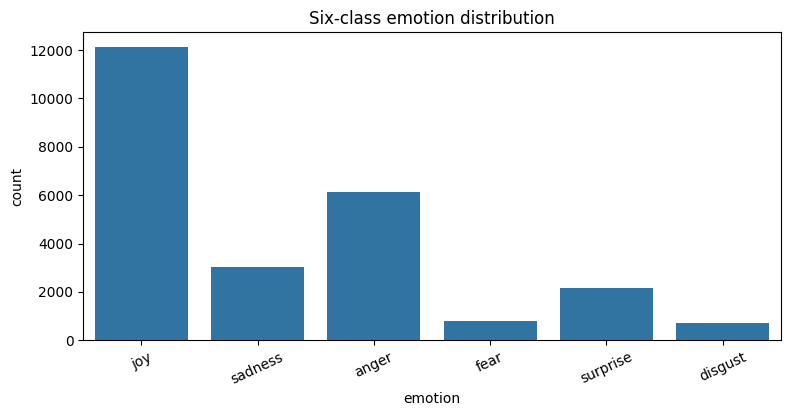

,text,labels,id,split,clean_text,emotion
3995,"Sweet, congrats!",15,ef97jpm,train,"sweet, congrats!",joy
18976,Man I love reddit.,18,eeibobj,train,man i love reddit.,joy
17462,I really wanted him to be wearing cowboy boots...,"8,9",eefygcl,train,i really wanted him to be wearing cowboy boots...,sadness
16367,I'm sorry to break the news to you. :(,24,eew3rud,train,i'm sorry to break the news to you.,sadness
17752,"I love the wire, never sad any thing bad about...","0,18",ee5s9e3,train,"i love the wire, never sad any thing bad about...",joy
23845,"America is not a country, it's a fucking busin...",2,edokegg,test,"america is not a country, it's a fucking busin...",anger
6892,"[NAME] bless you, fellow [NAME]! What a wonder...","0,20",efeddwq,train,"name bless you, fellow name ! what a wonderful...",joy
8225,Because it's straight up untrue. It's a new ce...,9,ee12lce,train,because it's straight up untrue. it's a new ce...,sadness
7955,You know more liberals want more gun control t...,3,eeqcwbt,train,you know more liberals want more gun control t...,anger
10819,“People said I was stupid for stretching out m...,3,ef4tymt,train,people said i was stupid for stretching out my...,anger


Filtered dataset shape: (24939, 6)
emotion
joy         12127
anger        6131
sadness      3019
surprise     2164
fear          790
disgust       708
Name: count, dtype: int64


In [14]:

LABEL_GROUPS = {
    "joy": ["joy", "amusement", "excitement", "gratitude", "love", "optimism", "pride", "relief"],
    "sadness": ["sadness", "grief", "remorse", "disappointment"],
    "anger": ["anger", "annoyance", "disapproval"],
    "fear": ["fear", "nervousness"],
    "surprise": ["surprise", "realization"],
    "disgust": ["disgust"]
}

CLASS_NAMES = ["joy", "sadness", "anger", "fear", "surprise", "disgust"]

emotion_to_class = {
    emotion: class_name
    for class_name, emotions in LABEL_GROUPS.items()
    for emotion in emotions
}

def map_labels(label_string):
    label_ids = [int(x) for x in label_string.split(",") if x.strip()]
    mapped_classes = set()

    for label_id in label_ids:
        if 0 <= label_id < len(emotion_names):
            emotion = emotion_names[label_id]
            if emotion in emotion_to_class:
                mapped_classes.add(emotion_to_class[emotion])

    if len(mapped_classes) == 1:
        return mapped_classes.pop()

    return None

df["emotion"] = df["labels"].apply(map_labels)
df = df.dropna(subset=["emotion"]).reset_index(drop=True)

plt.figure(figsize=(9, 4))
sns.countplot(data=df, x="emotion", order=CLASS_NAMES)
plt.title("Six-class emotion distribution")
plt.xticks(rotation=25)
plt.show()

display(df.sample(min(10, len(df)), random_state=SEED))
print("Filtered dataset shape:", df.shape)
print(df["emotion"].value_counts())


In [15]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-z0-9'!?.,\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["clean_text"] = df["text"].apply(clean_text)
label_to_id = {name: i for i, name in enumerate(CLASS_NAMES)}
df["label"] = df["emotion"].map(label_to_id)

train_df, temp_df = train_test_split(
    df, test_size=0.20, random_state=SEED, stratify=df["label"]
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, random_state=SEED, stratify=temp_df["label"]
)

print("Train:", train_df.shape, "Validation:", val_df.shape, "Test:", test_df.shape)

def tokenize(text):
    return re.findall(r"[a-z0-9]+|[!?.,]", text.lower())

counter = Counter()
for text in train_df["clean_text"]:
    counter.update(tokenize(text))

PAD_TOKEN, UNK_TOKEN = "<pad>", "<unk>"
vocab = {PAD_TOKEN: 0, UNK_TOKEN: 1}
for word, count in counter.items():
    if count >= 2:
        vocab[word] = len(vocab)

def encode_text(text):
    ids = [vocab.get(token, vocab[UNK_TOKEN]) for token in tokenize(text)[:MAX_LEN]]
    ids = ids + [vocab[PAD_TOKEN]] * (MAX_LEN - len(ids))
    return ids

X_train = np.array([encode_text(x) for x in train_df["clean_text"]], dtype=np.int64)
X_val = np.array([encode_text(x) for x in val_df["clean_text"]], dtype=np.int64)
X_test = np.array([encode_text(x) for x in test_df["clean_text"]], dtype=np.int64)

y_train = train_df["label"].to_numpy(dtype=np.int64)
y_val = val_df["label"].to_numpy(dtype=np.int64)
y_test = test_df["label"].to_numpy(dtype=np.int64)

print("Vocabulary size:", len(vocab), "| Sequence length:", MAX_LEN)

Train: (19951, 7) Validation: (2494, 7) Test: (2494, 7)
Vocabulary size: 8019 | Sequence length: 40


In [16]:
import gensim.downloader as api

glove = api.load("glove-wiki-gigaword-100")
EMBED_DIM = 100

embedding_matrix = np.random.normal(0, 0.05, (len(vocab), EMBED_DIM)).astype(np.float32)
embedding_matrix[vocab[PAD_TOKEN]] = 0

hits = 0
for word, idx in vocab.items():
    if word in glove:
        embedding_matrix[idx] = glove[word]
        hits += 1

print(f"GloVe coverage: {hits}/{len(vocab)} = {hits/len(vocab):.2%}")

[==================================================] 100.0% 128.1/128.1MB downloaded
GloVe coverage: 7826/8019 = 97.59%


In [17]:
class EmotionDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.long)
        self.y = torch.tensor(y, dtype=torch.long)
    def __len__(self):
        return len(self.y)
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

train_loader = DataLoader(EmotionDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(EmotionDataset(X_val, y_val), batch_size=BATCH_SIZE)
test_loader = DataLoader(EmotionDataset(X_test, y_test), batch_size=BATCH_SIZE)

class_weights = compute_class_weight(
    class_weight="balanced", classes=np.arange(NUM_CLASSES), y=y_train
)
class_weights = torch.tensor(class_weights, dtype=torch.float32, device=DEVICE)

In [18]:
class SequenceClassifier(nn.Module):
    def __init__(self, cell="lstm", bidirectional=False, attention=False, hidden_dim=128, dropout=0.3):
        super().__init__()
        self.embedding = nn.Embedding.from_pretrained(
            torch.tensor(embedding_matrix), freeze=False, padding_idx=0
        )
        self.attention = attention
        self.rnn = nn.LSTM(
            EMBED_DIM, hidden_dim, batch_first=True,
            bidirectional=bidirectional
        ) if cell == "lstm" else nn.GRU(
            EMBED_DIM, hidden_dim, batch_first=True,
            bidirectional=bidirectional
        )
        out_dim = hidden_dim * (2 if bidirectional else 1)
        if attention:
            self.attention_layer = nn.Linear(out_dim, 1)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(out_dim, NUM_CLASSES)

    def forward(self, x, return_attention=False):
        mask = (x != 0)
        embedded = self.embedding(x)
        outputs, _ = self.rnn(embedded)

        if self.attention:
            scores = self.attention_layer(outputs).squeeze(-1)
            scores = scores.masked_fill(~mask, -1e9)
            weights = torch.softmax(scores, dim=1)
            context = torch.sum(outputs * weights.unsqueeze(-1), dim=1)
        else:
            lengths = mask.sum(dim=1).clamp(min=1) - 1
            context = outputs[torch.arange(outputs.size(0), device=x.device), lengths]
            weights = None

        logits = self.fc(self.dropout(context))
        if return_attention:
            return logits, weights
        return logits

models = {
    "LSTM": SequenceClassifier(cell="lstm").to(DEVICE),
    "GRU": SequenceClassifier(cell="gru").to(DEVICE),
    "BiLSTM_Attention": SequenceClassifier(cell="lstm", bidirectional=True, attention=True).to(DEVICE)
}
print("Models ready:", list(models.keys()))

Models ready: ['LSTM', 'GRU', 'BiLSTM_Attention']


In [19]:
def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train() if training else model.eval()
    total_loss, all_preds, all_labels = 0, [], []

    for xb, yb in loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        if training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(training):
            logits = model(xb)
            loss = nn.CrossEntropyLoss(weight=class_weights)(logits, yb)
            if training:
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()

        total_loss += loss.item() * len(yb)
        all_preds.extend(logits.argmax(1).detach().cpu().numpy())
        all_labels.extend(yb.cpu().numpy())

    return total_loss / len(loader.dataset), accuracy_score(all_labels, all_preds), f1_score(
        all_labels, all_preds, average="macro"
    )

def train_model(model, name, epochs=EPOCHS):
    optimizer = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=1e-4)
    best_f1 = -1
    history = []
    best_path = f"/kaggle/working/{name}_best.pt"

    for epoch in range(epochs):
        train_loss, train_acc, train_f1 = run_epoch(model, train_loader, optimizer)
        val_loss, val_acc, val_f1 = run_epoch(model, val_loader)
        history.append([epoch+1, train_loss, val_loss, train_acc, val_acc, val_f1])
        print(f"{name} | Epoch {epoch+1}/{epochs} | train_loss={train_loss:.4f} | val_loss={val_loss:.4f} | val_acc={val_acc:.4f} | val_macro_f1={val_f1:.4f}")
        if val_f1 > best_f1:
            best_f1 = val_f1
            torch.save(model.state_dict(), best_path)

    model.load_state_dict(torch.load(best_path, map_location=DEVICE))
    return model, pd.DataFrame(history, columns=["epoch","train_loss","val_loss","train_acc","val_acc","val_macro_f1"])

def evaluate_torch_model(model, loader, title):
    model.eval()
    y_true, y_pred = [], []
    with torch.no_grad():
        for xb, yb in loader:
            logits = model(xb.to(DEVICE))
            y_pred.extend(logits.argmax(1).cpu().numpy())
            y_true.extend(yb.numpy())

    print("\n", title)
    print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, zero_division=0))
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(7, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(f"{title} - Confusion Matrix")
    plt.show()

    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro")
    }

LSTM | Epoch 1/5 | train_loss=1.5184 | val_loss=1.2087 | val_acc=0.6215 | val_macro_f1=0.5016
LSTM | Epoch 2/5 | train_loss=0.9508 | val_loss=0.9672 | val_acc=0.7169 | val_macro_f1=0.6277
LSTM | Epoch 3/5 | train_loss=0.7123 | val_loss=0.9600 | val_acc=0.7578 | val_macro_f1=0.6504
LSTM | Epoch 4/5 | train_loss=0.5628 | val_loss=0.9672 | val_acc=0.7418 | val_macro_f1=0.6345
LSTM | Epoch 5/5 | train_loss=0.4429 | val_loss=1.0393 | val_acc=0.7506 | val_macro_f1=0.6265

 LSTM
              precision    recall  f1-score   support

         joy       0.92      0.87      0.90      1213
     sadness       0.61      0.70      0.65       302
       anger       0.76      0.64      0.70       613
        fear       0.59      0.72      0.65        79
    surprise       0.55      0.66      0.60       216
     disgust       0.34      0.62      0.44        71

    accuracy                           0.76      2494
   macro avg       0.63      0.70      0.66      2494
weighted avg       0.78      0.76  

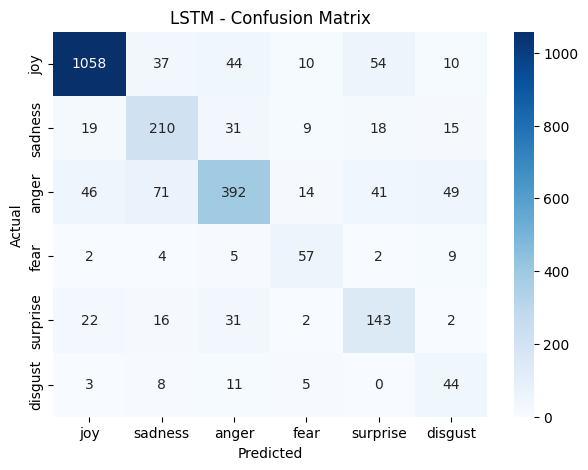

GRU | Epoch 1/5 | train_loss=1.3734 | val_loss=0.9910 | val_acc=0.6909 | val_macro_f1=0.5768
GRU | Epoch 2/5 | train_loss=0.8004 | val_loss=0.8620 | val_acc=0.7378 | val_macro_f1=0.6258
GRU | Epoch 3/5 | train_loss=0.6230 | val_loss=0.9704 | val_acc=0.7743 | val_macro_f1=0.6666
GRU | Epoch 4/5 | train_loss=0.4882 | val_loss=1.0008 | val_acc=0.7550 | val_macro_f1=0.6371
GRU | Epoch 5/5 | train_loss=0.3660 | val_loss=1.1691 | val_acc=0.7562 | val_macro_f1=0.6387

 GRU
              precision    recall  f1-score   support

         joy       0.93      0.86      0.90      1213
     sadness       0.71      0.69      0.70       302
       anger       0.68      0.75      0.71       613
        fear       0.62      0.65      0.63        79
    surprise       0.61      0.54      0.57       216
     disgust       0.35      0.65      0.45        71

    accuracy                           0.77      2494
   macro avg       0.65      0.69      0.66      2494
weighted avg       0.79      0.77      0.

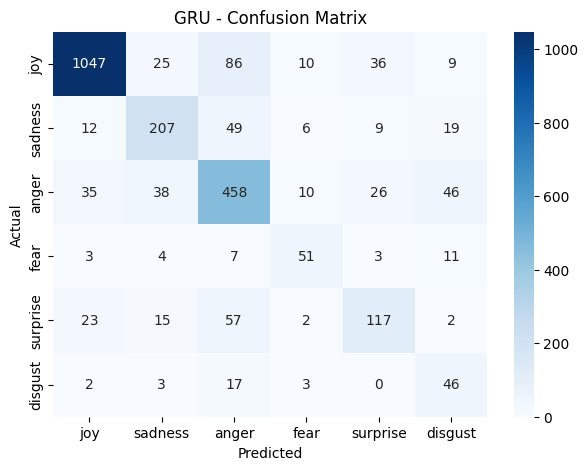

BiLSTM_Attention | Epoch 1/5 | train_loss=1.2602 | val_loss=0.9707 | val_acc=0.7322 | val_macro_f1=0.6260
BiLSTM_Attention | Epoch 2/5 | train_loss=0.7735 | val_loss=0.8606 | val_acc=0.7310 | val_macro_f1=0.6256
BiLSTM_Attention | Epoch 3/5 | train_loss=0.6290 | val_loss=0.8863 | val_acc=0.7514 | val_macro_f1=0.6352
BiLSTM_Attention | Epoch 4/5 | train_loss=0.5078 | val_loss=1.0376 | val_acc=0.7622 | val_macro_f1=0.6523
BiLSTM_Attention | Epoch 5/5 | train_loss=0.3901 | val_loss=1.1264 | val_acc=0.7522 | val_macro_f1=0.6403

 BiLSTM_Attention
              precision    recall  f1-score   support

         joy       0.91      0.88      0.90      1213
     sadness       0.68      0.69      0.68       302
       anger       0.75      0.64      0.69       613
        fear       0.65      0.73      0.69        79
    surprise       0.50      0.69      0.58       216
     disgust       0.42      0.61      0.50        71

    accuracy                           0.77      2494
   macro avg     

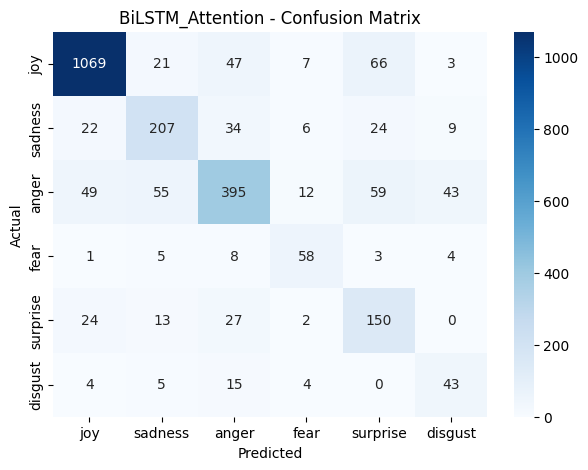

,accuracy,macro_f1
BiLSTM_Attention,0.770650,0.673136
GRU,0.772253,0.660825
LSTM,0.763432,0.655062


In [20]:
histories = {}
results = {}

for model_name, model in models.items():
    models[model_name], histories[model_name] = train_model(model, model_name)
    results[model_name] = evaluate_torch_model(models[model_name], test_loader, model_name)

display(pd.DataFrame(results).T.sort_values("macro_f1", ascending=False))

Predicted emotion: joy


,emotion,confidence
0,joy,9.983786e-01
1,sadness,1.355242e-03
2,anger,1.390450e-04
4,surprise,1.190703e-04
3,fear,7.771402e-06
5,disgust,3.334722e-07


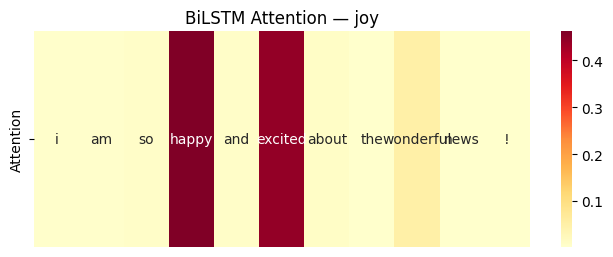

In [21]:
def show_attention(text, model=None):
    if model is None:
        model = models["BiLSTM_Attention"]
    cleaned = clean_text(text)
    tokens = tokenize(cleaned)[:MAX_LEN]
    ids = encode_text(cleaned)
    x = torch.tensor([ids], dtype=torch.long, device=DEVICE)

    model.eval()
    with torch.no_grad():
        logits, weights = model(x, return_attention=True)
        probs = torch.softmax(logits, dim=1)[0].cpu().numpy()
        attention = weights[0, :len(tokens)].cpu().numpy()

    pred = CLASS_NAMES[int(np.argmax(probs))]
    print("Predicted emotion:", pred)
    display(pd.DataFrame({"emotion": CLASS_NAMES, "confidence": probs}).sort_values("confidence", ascending=False))

    plt.figure(figsize=(max(8, len(tokens)*0.55), 2.8))
    sns.heatmap([attention], annot=[tokens], fmt="", cmap="YlOrRd",
                cbar=True, xticklabels=False, yticklabels=["Attention"])
    plt.title(f"BiLSTM Attention — {pred}")
    plt.show()

show_attention("I am so happy and excited about the wonderful news!")

In [38]:
import torch
import numpy as np
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.metrics import accuracy_score, f1_score
from torch.optim import AdamW
from tqdm.auto import tqdm
import copy
import os

MODEL_CHECKPOINT = "distilbert-base-uncased"
NUM_CLASSES = len(CLASS_NAMES)
MAX_LENGTH = 128
BATCH_SIZE = 16
EPOCHS = 3
LEARNING_RATE = 2e-5

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

label_to_id = {name: i for i, name in enumerate(CLASS_NAMES)}

train_df = df[df["split"] == "train"].copy()
val_df = df[df["split"] == "validation"].copy()
test_df = df[df["split"] == "test"].copy()

for frame in [train_df, val_df, test_df]:
    frame["label"] = frame["emotion"].map(label_to_id)
    frame["clean_text"] = frame["text"].fillna("").astype(str).str.strip()
    frame.dropna(subset=["label"], inplace=True)
    frame["label"] = frame["label"].astype(int)

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

tokenizer = AutoTokenizer.from_pretrained(MODEL_CHECKPOINT)

class EmotionDataset(Dataset):
    def __init__(self, frame):
        self.texts = frame["clean_text"].tolist()
        self.labels = frame["label"].tolist()

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, index):
        encoding = tokenizer(
            self.texts[index],
            truncation=True,
            max_length=MAX_LENGTH,
            padding="max_length",
            return_tensors="pt"
        )

        return {
            "input_ids": encoding["input_ids"].squeeze(0),
            "attention_mask": encoding["attention_mask"].squeeze(0),
            "labels": torch.tensor(self.labels[index], dtype=torch.long)
        }

train_dataset = EmotionDataset(train_df)
val_dataset = EmotionDataset(val_df)
test_dataset = EmotionDataset(test_df)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE
)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_CHECKPOINT,
    num_labels=NUM_CLASSES,
    id2label={i: name for i, name in enumerate(CLASS_NAMES)},
    label2id=label_to_id
)

model.to(device)

optimizer = AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=0.01
)

best_f1 = 0
best_model_state = None

for epoch in range(EPOCHS):

    model.train()
    total_loss = 0

    progress = tqdm(train_loader, desc=f"Epoch {epoch + 1}/{EPOCHS}")

    for batch in progress:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        optimizer.zero_grad()

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        loss = outputs.loss
        loss.backward()

        optimizer.step()

        total_loss += loss.item()
        progress.set_postfix(loss=loss.item())

    model.eval()

    val_preds = []
    val_labels = []
    val_loss = 0

    with torch.no_grad():

        for batch in val_loader:

            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels
            )

            val_loss += outputs.loss.item()

            preds = torch.argmax(outputs.logits, dim=1)

            val_preds.extend(preds.cpu().numpy())
            val_labels.extend(labels.cpu().numpy())

    accuracy = accuracy_score(val_labels, val_preds)
    macro_f1 = f1_score(val_labels, val_preds, average="macro")

    print(f"\nEpoch: {epoch + 1}")
    print(f"Train Loss: {total_loss / len(train_loader):.4f}")
    print(f"Validation Loss: {val_loss / len(val_loader):.4f}")
    print(f"Validation Accuracy: {accuracy:.4f}")
    print(f"Validation Macro F1: {macro_f1:.4f}")

    if macro_f1 > best_f1:
        best_f1 = macro_f1
        best_model_state = copy.deepcopy(model.state_dict())

model.load_state_dict(best_model_state)

SAVE_PATH = "/kaggle/working/distilbert_emotion"

os.makedirs(SAVE_PATH, exist_ok=True)

model.save_pretrained(SAVE_PATH)
tokenizer.save_pretrained(SAVE_PATH)

print("\nBest Validation Macro F1:", best_f1)
print("Best model saved successfully!")


Device: cuda
Train: (19967, 7)
Validation: (2473, 7)
Test: (2499, 7)


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

... (7 outputs left out)

Epoch 3/3:   0%|          | 0/1248 [00:00<?, ?it/s]


Epoch: 3
Train Loss: 0.2986
Validation Loss: 0.5516
Validation Accuracy: 0.8273
Validation Macro F1: 0.7229


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Best Validation Macro F1: 0.742501846435759
Best model saved successfully!


In [40]:

model.eval()

test_preds = []
test_labels = []

with torch.no_grad():

    for batch in tqdm(test_loader, desc="Testing"):

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        preds = torch.argmax(outputs.logits, dim=1)

        test_preds.extend(preds.cpu().numpy())
        test_labels.extend(labels.cpu().numpy())

test_accuracy = accuracy_score(test_labels, test_preds)
test_macro_f1 = f1_score(test_labels, test_preds, average="macro")
test_weighted_f1 = f1_score(test_labels, test_preds, average="weighted")

print("Test Accuracy:", round(test_accuracy, 4))
print("Test Macro F1:", round(test_macro_f1, 4))
print("Test Weighted F1:", round(test_weighted_f1, 4))


Testing:   0%|          | 0/157 [00:00<?, ?it/s]

Test Accuracy: 0.8171
Test Macro F1: 0.7249
Test Weighted F1: 0.8146


In [42]:
model.eval()

bert_preds = []
bert_true = []

with torch.no_grad():
    for batch in test_loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        preds = torch.argmax(outputs.logits, dim=1)

        bert_preds.extend(preds.cpu().numpy())
        bert_true.extend(labels.cpu().numpy())

bert_report = classification_report(
    bert_true,
    bert_preds,
    labels=list(range(len(CLASS_NAMES))),
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0
)

bert_per_class = pd.DataFrame({
    emotion: {
        "precision": bert_report[emotion]["precision"],
        "recall": bert_report[emotion]["recall"],
        "f1": bert_report[emotion]["f1-score"]
    }
    for emotion in CLASS_NAMES
}).T

display(bert_per_class)


,precision,recall,f1
joy,0.901135,0.954506,0.927053
sadness,0.742972,0.649123,0.692884
anger,0.800000,0.746914,0.772546
fear,0.752941,0.744186,0.748538
surprise,0.593750,0.658009,0.624230
disgust,0.642857,0.535714,0.584416


In [46]:

import pickle
import json
import os
import torch

ARTIFACTS_PATH = "/kaggle/working/emotion_artifacts"
os.makedirs(ARTIFACTS_PATH, exist_ok=True)

bert_path = os.path.join(ARTIFACTS_PATH, "distilbert")
os.makedirs(bert_path, exist_ok=True)

model.save_pretrained(bert_path)
tokenizer.save_pretrained(bert_path)

for name, model_arch in models.items():
    torch.save(
        model_arch.state_dict(),
        os.path.join(ARTIFACTS_PATH, f"{name}.pt")
    )

with open(os.path.join(ARTIFACTS_PATH, "vocab.pkl"), "wb") as f:
    pickle.dump(vocab, f)

with open(os.path.join(ARTIFACTS_PATH, "config.json"), "w") as f:
    json.dump({
        "classes": CLASS_NAMES,
        "max_len": MAX_LEN,
        "embedding_dim": EMBED_DIM,
        "label_to_id": label_to_id
    }, f, indent=2)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [48]:

print("Available variables:")

for name in list(globals().keys()):
    if any(key in name.lower() for key in [
        "test", "pred", "true", "loader", "model", "comparison"
    ]):
        print(name, type(globals()[name]).__name__)

print("\nModel names:", list(models.keys()))


Available variables:
__loader__ NoneType
DataLoader type
train_test_split function
test_raw DataFrame
test_df DataFrame
X_test ndarray
y_test ndarray
train_loader DataLoader
val_loader DataLoader
test_loader DataLoader
models dict
train_model function
evaluate_torch_model function
model_name str
model DistilBertForSequenceClassification
AutoModelForSequenceClassification type
MODEL_CHECKPOINT str
test_dataset EmotionDataset
best_model_state OrderedDict
val_preds list
preds Tensor
test_preds list
test_labels list
test_accuracy float
test_macro_f1 float
test_weighted_f1 float
bert_preds list
bert_true list
model_arch SequenceClassifier

Model names: ['LSTM', 'GRU', 'BiLSTM_Attention']


In [50]:
import inspect

print(inspect.signature(evaluate_torch_model))
print(inspect.getsource(evaluate_torch_model))

(model, loader, title)
def evaluate_torch_model(model, loader, title):
    model.eval()
    y_true, y_pred = [], []
    with torch.no_grad():
        for xb, yb in loader:
            logits = model(xb.to(DEVICE))
            y_pred.extend(logits.argmax(1).cpu().numpy())
            y_true.extend(yb.numpy())

    print("\n", title)
    print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, zero_division=0))
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(7, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(f"{title} - Confusion Matrix")
    plt.show()

    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro")
    }




 LSTM
              precision    recall  f1-score   support

         joy       0.92      0.87      0.90      1213
     sadness       0.61      0.70      0.65       302
       anger       0.76      0.64      0.70       613
        fear       0.59      0.72      0.65        79
    surprise       0.55      0.66      0.60       216
     disgust       0.34      0.62      0.44        71

    accuracy                           0.76      2494
   macro avg       0.63      0.70      0.66      2494
weighted avg       0.78      0.76      0.77      2494



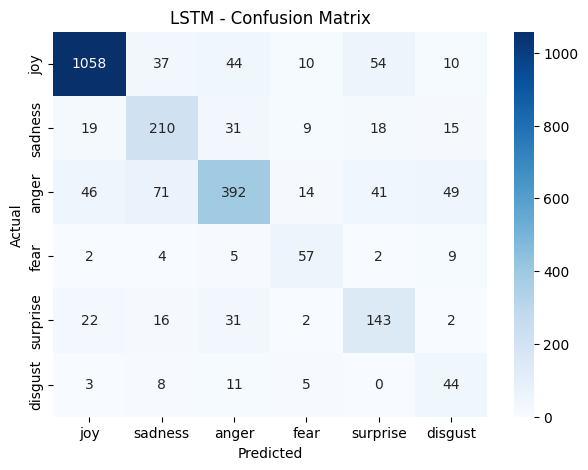


 GRU
              precision    recall  f1-score   support

         joy       0.93      0.86      0.90      1213
     sadness       0.71      0.69      0.70       302
       anger       0.68      0.75      0.71       613
        fear       0.62      0.65      0.63        79
    surprise       0.61      0.54      0.57       216
     disgust       0.35      0.65      0.45        71

    accuracy                           0.77      2494
   macro avg       0.65      0.69      0.66      2494
weighted avg       0.79      0.77      0.78      2494



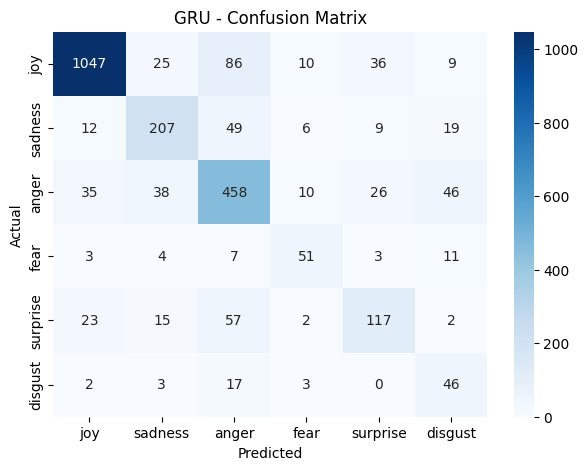


 BiLSTM_Attention
              precision    recall  f1-score   support

         joy       0.91      0.88      0.90      1213
     sadness       0.68      0.69      0.68       302
       anger       0.75      0.64      0.69       613
        fear       0.65      0.73      0.69        79
    surprise       0.50      0.69      0.58       216
     disgust       0.42      0.61      0.50        71

    accuracy                           0.77      2494
   macro avg       0.65      0.71      0.67      2494
weighted avg       0.79      0.77      0.78      2494



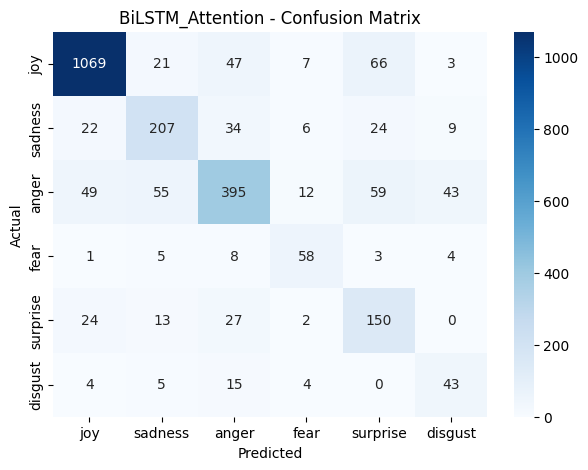

,accuracy,macro_f1
Model,,
LSTM,0.763432,0.655062
GRU,0.772253,0.660825
BiLSTM_Attention,0.770650,0.673136


In [51]:
from torch.utils.data import TensorDataset, DataLoader
import pandas as pd

X_test_tensor = torch.tensor(X_test, dtype=torch.long)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)

test_loader_classic = DataLoader(
    TensorDataset(X_test_tensor, y_test_tensor),
    batch_size=64,
    shuffle=False
)

results = {}

for name, model_arch in models.items():
    metrics = evaluate_torch_model(
        model_arch,
        test_loader_classic,
        name
    )
    results[name] = metrics

comparison = pd.DataFrame(results).T
comparison.index.name = "Model"

comparison

In [55]:
import torch
import pandas as pd
import gradio as gr
from datetime import datetime
from transformers import pipeline

# ---------------- Model ----------------
MODEL_PATH = "/kaggle/working/emotion_artifacts/distilbert"
DEVICE = 0 if torch.cuda.is_available() else -1

emotion_pipe = pipeline(
    "text-classification", model=MODEL_PATH, tokenizer=MODEL_PATH,
    device=DEVICE, top_k=None
)

# Class names: taken from the model config; falls back to the standard 6-class order
DEFAULT_NAMES = ["sadness", "joy", "love", "anger", "fear", "surprise"]
raw = list(emotion_pipe.model.config.id2label.values())
if all(str(l).startswith("LABEL_") for l in raw):
    LABEL_MAP = {f"LABEL_{i}": n for i, n in enumerate(DEFAULT_NAMES)}
    CLASS_NAMES = DEFAULT_NAMES
else:
    LABEL_MAP = {l: str(l).lower() for l in raw}
    CLASS_NAMES = [str(l).lower() for l in raw]

# ---------------- Reference data ----------------
INFO = {
    "sadness":  ("😢", "#3b82f6", "Grief, disappointment, or loss",        "I feel so lonely and hopeless today."),
    "joy":      ("😄", "#f59e0b", "Happiness, satisfaction, optimism",     "I am really excited about this!"),
    "love":     ("❤️", "#ec4899", "Affection, warmth, appreciation",       "I adore my family, they mean everything."),
    "anger":    ("😠", "#ef4444", "Frustration, irritation, hostility",    "I am furious about how they treated me!"),
    "fear":     ("😨", "#8b5cf6", "Anxiety, worry, nervousness",           "I am terrified of what might happen tomorrow."),
    "surprise": ("😲", "#10b981", "Astonishment at something unexpected",  "Wow, I never expected this to happen!"),
}
def info(n): return INFO.get(n, ("🙂", "#64748b", "-", "-"))

REF_TABLE = pd.DataFrame([
    {"Emotion": f"{info(n)[0]} {n.capitalize()}", "Meaning": info(n)[2], "Example": info(n)[3]}
    for n in CLASS_NAMES
])

MODEL_TABLE = pd.DataFrame({
    "Item": ["Model", "Task", "Number of classes", "Max tokens", "Device", "Classes"],
    "Value": ["Fine-tuned DistilBERT", "Emotion Classification (Text)", str(len(CLASS_NAMES)),
              "128", "GPU" if DEVICE == 0 else "CPU", ", ".join(CLASS_NAMES)],
})

def level(p):
    return "🟢 High" if p >= 80 else "🟡 Medium" if p >= 50 else "🔴 Low"

def card(title, body, color="#6366f1"):
    return (f"<div style='padding:20px;border-radius:16px;border:2px solid {color};"
            f"background:{color}15;text-align:center'>"
            f"<div style='font-size:15px;opacity:.8'>{title}</div>{body}</div>")

WAITING = card("Waiting for input...", "<div style='font-size:48px'>💬</div>")
HIST_COLS = ["Time", "Text", "Emotion", "Confidence %"]

# ---------------- Inference ----------------
def predict(text, history):
    history = history or []
    if not text or not text.strip():
        return (card("⚠️", "<div style='font-size:20px'>Please enter a sentence first</div>", "#f59e0b"),
                pd.DataFrame({"Emotion": CLASS_NAMES, "Confidence %": [0.0] * len(CLASS_NAMES)}),
                pd.DataFrame(), pd.DataFrame(history, columns=HIST_COLS), history)

    out = emotion_pipe(text, truncation=True, max_length=128)[0]
    scores = {LABEL_MAP.get(o["label"], str(o["label"]).lower()): float(o["score"]) * 100 for o in out}
    scores = {n: scores.get(n, 0.0) for n in CLASS_NAMES}

    ranked = sorted(scores.items(), key=lambda x: x[1], reverse=True)
    top, top_p = ranked[0]
    emoji, color, meaning, _ = info(top)

    result_card = card(
        "Dominant Emotion",
        f"<div style='font-size:56px;margin:6px 0'>{emoji}</div>"
        f"<div style='font-size:30px;font-weight:700;color:{color}'>{top.upper()}</div>"
        f"<div style='font-size:18px;margin-top:4px'>Confidence: <b>{top_p:.1f}%</b> — {level(top_p)}</div>"
        f"<div style='opacity:.75;margin-top:6px'>{meaning}</div>", color)

    chart = pd.DataFrame({"Emotion": [f"{info(n)[0]} {n}" for n in scores],
                          "Confidence %": [round(v, 2) for v in scores.values()]})

    table = pd.DataFrame([{
        "Rank": i + 1,
        "Emotion": f"{info(n)[0]} {n.capitalize()}",
        "Confidence %": round(p, 2),
        "Level": level(p),
        "Gap vs. Top": "—" if i == 0 else f"-{top_p - p:.2f}",
    } for i, (n, p) in enumerate(ranked)])

    history = ([[datetime.now().strftime("%H:%M:%S"), text[:70], f"{emoji} {top}", round(top_p, 1)]]
               + history)[:10]
    return result_card, chart, table, pd.DataFrame(history, columns=HIST_COLS), history

# ---------------- UI ----------------
theme = gr.themes.Soft(primary_hue="indigo", secondary_hue="pink", neutral_hue="slate",
                       font=[gr.themes.GoogleFont("Inter"), "sans-serif"])

CSS = ".gradio-container{max-width:1100px!important;margin:auto} footer{display:none!important}"

with gr.Blocks(theme=theme, css=CSS, title="Emotion Classifier") as demo:
    gr.HTML("<div style='text-align:center;padding:10px'>"
            "<h1 style='margin:0'>🧠 Emotion Classification</h1>"
            "<p style='opacity:.7'>Six-class text emotion detection using fine-tuned DistilBERT</p></div>")
    hist_state = gr.State([])

    with gr.Row():
        with gr.Column(scale=5):
            inp = gr.Textbox(lines=5, label="✍️ Enter a sentence",
                             placeholder="I am really excited about this!")
            with gr.Row():
                clear_btn = gr.Button("🗑️ Clear", variant="secondary")
                run_btn = gr.Button("🔍 Analyze Emotion", variant="primary")
            gr.Examples([[v[3]] for v in INFO.values()], inputs=inp, label="Try an example")
        with gr.Column(scale=4):
            result = gr.HTML(WAITING)

    with gr.Tabs():
        with gr.Tab("📊 Detailed Results"):
            with gr.Row():
                chart = gr.BarPlot(x="Emotion", y="Confidence %", title="Confidence across emotions",
                                   y_lim=[0, 100], height=340)
                table = gr.Dataframe(label="Emotion Ranking", interactive=False, wrap=True)
        with gr.Tab("🕘 History"):
            hist_df = gr.Dataframe(value=pd.DataFrame(columns=HIST_COLS), label="Last 10 analyses",
                                   interactive=False, wrap=True)
        with gr.Tab("📚 Emotion Guide"):
            gr.Dataframe(value=REF_TABLE, label="What each class means", interactive=False, wrap=True)
        with gr.Tab("⚙️ Model Info"):
            gr.Dataframe(value=MODEL_TABLE, label="Model details", interactive=False, wrap=True)

    outs = [result, chart, table, hist_df, hist_state]
    run_btn.click(predict, [inp, hist_state], outs)
    inp.submit(predict, [inp, hist_state], outs)
    clear_btn.click(lambda: ("", WAITING), None, [inp, result])

demo.launch(share=True)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

* Running on local URL:  http://127.0.0.1:7862
* Running on public URL: https://312072e5a54ea5a64d.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
